<a href="https://colab.research.google.com/github/MariaMinottaZ/movie-review-sentiment-analysis/blob/main/Distil_BERT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In this notebook there will be trained and tested a BERT models

# Import dataset

In [1]:
import kagglehub

path = kagglehub.dataset_download("lakshmi25npathi/imdb-dataset-of-50k-movie-reviews")

print("Path to dataset files:", path)

100%|██████████| 25.7M/25.7M [00:00<00:00, 81.1MB/s]


Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews/versions/1


Extract content

In [2]:
import pandas as pd
import os

csv_files = []

for root, dirs, files in os.walk(path):
    for file in files:
        if file.endswith(".csv"):
            csv_files.append(os.path.join(root, file))

print(csv_files)

['/root/.cache/kagglehub/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews/versions/1/IMDB Dataset.csv']


In [3]:
columns = [
    "review",
    "sentiment"
]

df = pd.read_csv(
    csv_files[0],
    encoding="ISO-8859-1",
    header=None,
    names=columns
)

 # Preprocessing

Delete outlier

In [4]:
df = df[df["sentiment"] != "sentiment"].copy()

Clean text

In [5]:
import re

def clean_text(text):

    text = text.lower()

    text = re.sub(r"<br\s*/?>", " ", text)

    text = re.sub(r"http\S+|www\.\S+", "", text)

    text = re.sub(r"https\S+|www\.\S+", "", text)

    text = re.sub(r"[^a-z\s]", " ", text)

    text = re.sub(r"\s+", " ", text).strip()

    return text

Applied to reviews

In [6]:
df["clean_text"] = df["review"].apply(clean_text)

# Creating model

## Import model and training

In [7]:
!pip install transformers datasets accelerate evaluate

Split

In [8]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    df["clean_text"],
    df["sentiment"],
    test_size=0.2,
    random_state=42,
    stratify=df["sentiment"]
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

In [9]:
y_train = y_train.map({
    "negative": 0,
    "positive": 1
})

y_val = y_val.map({
    "negative": 0,
    "positive": 1
})

y_test = y_test.map({
    "negative": 0,
    "positive": 1
})

Obtain BERT and its tokenizer

In [10]:
from transformers import AutoTokenizer

model_name = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Prepare data

In [11]:
from datasets import Dataset

train_df = Dataset.from_dict({
    "text": X_train.tolist(),
    "labels": y_train.astype(int).tolist()
})

val_df = Dataset.from_dict({
    "text": X_val.tolist(),
    "labels": y_val.astype(int).tolist()
})

test_df = Dataset.from_dict({
    "text": X_test.tolist(),
    "labels": y_test.astype(int).tolist()
})

Apply tokenizer

In [12]:
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=256
    )

train_tokenized = train_df.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"]
)

val_tokenized = val_df.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"]
)

test_tokenized = test_df.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"]
)

Map:   0%|          | 0/40000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Import model

In [13]:
from transformers import AutoModelForSequenceClassification

model_distilbert = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [14]:
import numpy as np
import evaluate

from transformers import (
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding
)

accuracy = evaluate.load("accuracy")
f1 = evaluate.load("f1")

def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy.compute(
            predictions=predictions,
            references=labels
        )["accuracy"],

        "f1": f1.compute(
            predictions=predictions,
            references=labels
        )["f1"]
    }

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

training_args = TrainingArguments(
    output_dir="./bert_results",

    num_train_epochs=3,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,

    learning_rate=2e-5,
    weight_decay=0.01,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="f1",

    report_to="none"
)

trainer = Trainer(
    model=model_distilbert,
    args=training_args,

    train_dataset=train_tokenized,
    eval_dataset=val_tokenized,

    processing_class=tokenizer,
    data_collator=data_collator,

    compute_metrics=compute_metrics
)

trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.277819,0.280190,0.912200,0.914972
2,0.176160,0.310667,0.917800,0.916650
3,0.106677,0.369144,0.925000,0.925343


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=15000, training_loss=0.20380288976033528, metrics={'train_runtime': 2973.9403, 'train_samples_per_second': 40.351, 'train_steps_per_second': 5.044, 'total_flos': 7906449156182016.0, 'train_loss': 0.20380288976033528, 'epoch': 3.0})

## Metrics

In [17]:
predictions = trainer.predict(test_tokenized)

y_pred = np.argmax(
    predictions.predictions,
    axis=1
)

y_true = np.array(y_test)

Confusion matrix

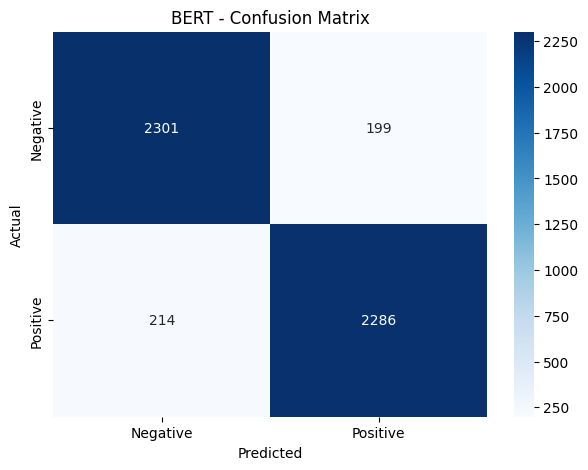

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("BERT - Confusion Matrix")

plt.show()

Other metrics

In [20]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Accuracy:", accuracy_score(y_true, y_pred))

print("Precision:", precision_score(y_true, y_pred))

print("Recall:", recall_score(y_true, y_pred))

print("F1 Score:", f1_score(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Negative", "Positive"]
))

Accuracy: 0.9174
Precision: 0.9199195171026157
Recall: 0.9144
F1 Score: 0.9171514543630893

Classification Report:
              precision    recall  f1-score   support

    Negative       0.91      0.92      0.92      2500
    Positive       0.92      0.91      0.92      2500

    accuracy                           0.92      5000
   macro avg       0.92      0.92      0.92      5000
weighted avg       0.92      0.92      0.92      5000



# Testing model

Real reviews:

-"The new hunger games movie is absolutely beautiful. The sets, designs, outfits, environment. Its all so gorgeous. The acting is also really engaging. The comedy mostly comes from the character acting. It was very fun. Ceasar, I love you. The thing that makes this movie meh is the pacing. Every bit and moment goes by so fast yet it still expects you to take it seriously. Character comes in, character dies. Over and over. Its REALLY bad, the pacing. It makes it really difficult to connect with the characters and/or events, just like how the book did. To be fair, the book is like 4 hours of story telling, so this movie HAD to compress it, but that comes with a cost. I definently prefer the book."

7/10

-"Before watching The Odyssey, I'd seen loads of mixed reviews, so I went in with an open mind and honestly wasn't expecting much. I couldn't have been more wrong. I was hooked from start to finish. It's one of those films that completely pulls you in, and I enjoyed every minute of it. The performances were outstanding across the board. With a cast like this, you'd expect quality, but everyone played their part brilliantly and really brought the story to life. What I appreciated most was how immersive it felt. For a film that's nearly three hours long, I never found myself checking my phone or thinking about anything else. It was gripping from start to finish. Everyone's entitled to their own opinion, but I absolutely loved this film and would recommend it to anyone."

10/10

-"The most entertaining part of this entire movie was reading these hilariously bad reviews. It was SO boring and hard to watch."

2/10

-"This left me speechless......and not in a breath-taking Shawshank Redemption type way! I literally wanted to rip my arm off and throw it at the TV it was so bad. My husband and I made a bet with one another as to who could keep watching it the longest........the loser buying the weekend beers! I was quite happy to lose that night. I had no idea what was going on, it kept skipping from one sketch to another with no plot, no reason and NO POINT! Awful acting, awful impressions, awful film! Pretty much is what it says on the tin, A Disaster. Do not watch this movie."


1/10


In [21]:
test_reviews = [
    "The new hunger games movie is absolutely beautiful. The sets, designs, outfits, environment. Its all so gorgeous. The acting is also really engaging. The comedy mostly comes from the character acting. It was very fun. Ceasar, I love you. The thing that makes this movie meh is the pacing. Every bit and moment goes by so fast yet it still expects you to take it seriously. Character comes in, character dies. Over and over. Its REALLY bad, the pacing. It makes it really difficult to connect with the characters and/or events, just like how the book did. To be fair, the book is like 4 hours of story telling, so this movie HAD to compress it, but that comes with a cost. I definently prefer the book.",
    "Before watching The Odyssey, I'd seen loads of mixed reviews, so I went in with an open mind and honestly wasn't expecting much. I couldn't have been more wrong. I was hooked from start to finish. It's one of those films that completely pulls you in, and I enjoyed every minute of it. The performances were outstanding across the board. With a cast like this, you'd expect quality, but everyone played their part brilliantly and really brought the story to life. What I appreciated most was how immersive it felt. For a film that's nearly three hours long, I never found myself checking my phone or thinking about anything else. It was gripping from start to finish. Everyone is entitled to their own opinion, but I absolutely loved this film and would recommend it to anyone.",
    "The most entertaining part of this entire movie was reading these hilariously bad reviews. It was SO boring and hard to watch.",
    "This left me speechless......and not in a breath-taking Shawshank Redemption type way! I literally wanted to rip my arm off and throw it at the TV it was so bad. My husband and I made a bet with one another as to who could keep watching it the longest........the loser buying the weekend beers! I was quite happy to lose that night. I had no idea what was going on, it kept skipping from one sketch to another with no plot, no reason and NO POINT! Awful acting, awful impressions, awful film! Pretty much is what it says on the tin, A Disaster. Do not watch this movie."
]

In [26]:
import torch
import torch.nn.functional as F

def predict_sentiment(review):

    model_distilbert.eval()

    inputs = tokenizer(
        review,
        return_tensors="pt",
        truncation=True,
        max_length=256,
        padding=True
    )

    device = next(model_distilbert.parameters()).device

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():

        outputs = model_distilbert(**inputs)

        probabilities = F.softmax(
            outputs.logits,
            dim=1
        )

    predicted_class = torch.argmax(
        probabilities,
        dim=1
    ).item()

    labels = {
        0: "Negative",
        1: "Positive"
    }

    return {
        "sentiment": labels[predicted_class],
        "probability_negative": probabilities[0][0].item(),
        "probability_positive": probabilities[0][1].item()
    }

In [28]:
for review in test_reviews:

    result = predict_sentiment(review)

    print("Review:", review)
    print("Sentiment:", result["sentiment"])
    print("Positive probability:", round(result["probability_positive"], 4))
    print("Negative probability:", round(result["probability_negative"], 4))
    print("-" * 60)

Review: The new hunger games movie is absolutely beautiful. The sets, designs, outfits, environment. Its all so gorgeous. The acting is also really engaging. The comedy mostly comes from the character acting. It was very fun. Ceasar, I love you. The thing that makes this movie meh is the pacing. Every bit and moment goes by so fast yet it still expects you to take it seriously. Character comes in, character dies. Over and over. Its REALLY bad, the pacing. It makes it really difficult to connect with the characters and/or events, just like how the book did. To be fair, the book is like 4 hours of story telling, so this movie HAD to compress it, but that comes with a cost. I definently prefer the book.
Sentiment: Negative
Positive probability: 0.004
Negative probability: 0.996
------------------------------------------------------------
Review: Before watching The Odyssey, I'd seen loads of mixed reviews, so I went in with an open mind and honestly wasn't expecting much. I couldn't have 

# Save

In [29]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Model

In [30]:
trainer.save_model(
    '/content/drive/MyDrive/Sentiment_Analysis/models/distilbert.keras'
)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

##Tokenizer

In [31]:
tokenizer.save_pretrained(
  '/content/drive/MyDrive/Sentiment_Analysis/models/tokenizer_distilbert.pkl'
)

('/content/drive/MyDrive/Sentiment_Analysis/models/tokenizer_distilbert.pkl/tokenizer_config.json',
 '/content/drive/MyDrive/Sentiment_Analysis/models/tokenizer_distilbert.pkl/tokenizer.json')